In [1]:
import numpy as np
from numpy import linalg
import matplotlib.pyplot as plt
from skimage import io
from skimage.transform import AffineTransform, SimilarityTransform
from skimage.measure import ransac
from vol_rec_lm.simulation import seed_volume, gaussian_3d, PSF
from vol_rec_lm.volume_reconstruction_localisation import localise_volume
from scipy import signal, ndimage
from tqdm import tqdm
from itertools import combinations, permutations
from skimage.feature import plot_matched_features
from registration.point_matching.point_matching import *
import pandas as pd
from scipy.ndimage import affine_transform
from scipy.linalg import svd
import math
import tifffile
from skimage.restoration import unwrap_phase
from matplotlib.colors import PowerNorm

ModuleNotFoundError: No module named 'numpy'

# Registration

In [2]:
def remove_near_duplicates(data, tolerance_z, tolerance_y, tolerance_x):
    results = [data[0, :]]
    for i in range(data.shape[0] - 1):
        keep = True
        for result in results:
            if (
                is_near(data[i + 1, 0], result[0], tolerance_z)
                & is_near(data[i + 1, 1], result[1], tolerance_y)
                & is_near(data[i + 1, 2], result[2], tolerance_x)
            ):
                keep = False
                break
        if keep:
            results.append(data[i + 1, :])
    return np.array(results)


def is_near(num, target, tolerance):
    ul = num + tolerance
    ll = num - tolerance
    return (target <= ul) and (target >= ll)

### Localise beads

In [3]:
################### Process #####################
# Pre downsampled in imagej...
arm_1 = io.imread("data/reconstruction_1/registration/reg_8.1_processed.tif")
arm_2 = io.imread("data/reconstruction_1/registration/reg_8.2_processed.tif")

downsample_factor = 2
arm_1 = arm_1[::downsample_factor, ::downsample_factor, ::downsample_factor]
arm_2 = arm_2[::downsample_factor, ::downsample_factor, ::downsample_factor]
normalised_arm_1 = (arm_1 - np.min(arm_1)) / (np.max(arm_1) - np.min(arm_1))
normalised_arm_2 = (arm_2 - np.min(arm_2)) / (np.max(arm_2) - np.min(arm_2))

# Remove background
bg_sub_1 = np.where((normalised_arm_1 - 0.01) < 0, 0, normalised_arm_1)
bg_sub_2 = np.where((normalised_arm_2 - 0.01) < 0, 0, normalised_arm_2)

In [4]:
#################### Localise #####################
arm_1_df = localise_volume(
    bg_sub_1,
    min_sigma=0.01,
    max_sigma=5,
    threshold=0.1,
    patch_crop=1,
    sigma_psf=1,
    n_jobs=-1,
)

arm_2_df = localise_volume(
    bg_sub_2,
    min_sigma=0.001,
    max_sigma=5,
    threshold=0.001,
    patch_crop=1,
    sigma_psf=1,
    n_jobs=-1,
)

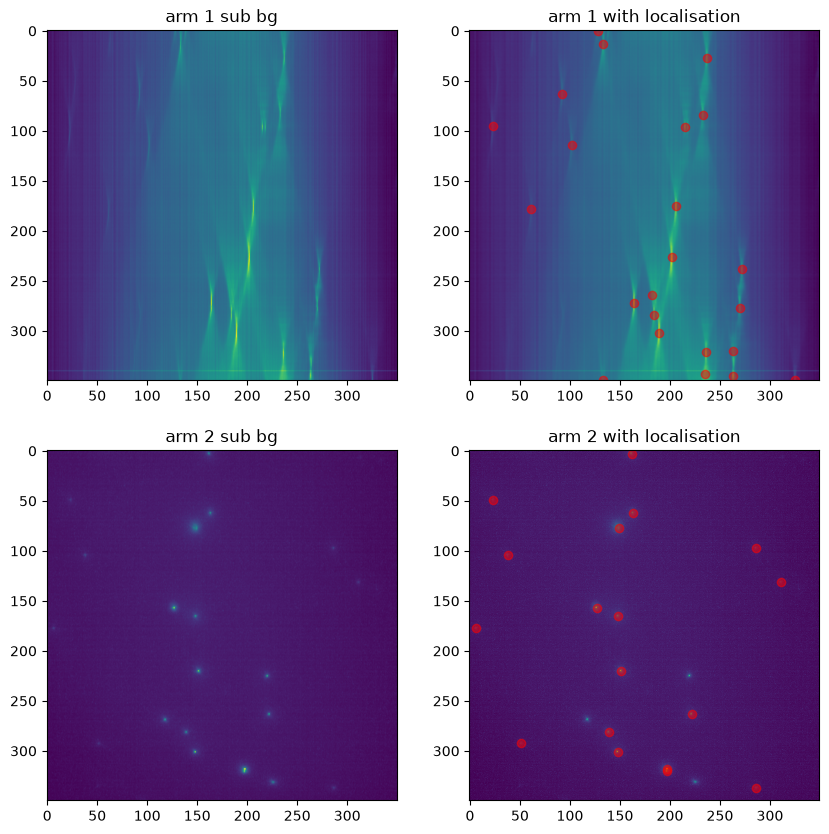

In [5]:
# Final processing to remove duplicate localisation
# bead_locs_1 = remove_near_duplicates(np.array(points_1), 40, 40, 40)
# bead_locs_2 = remove_near_duplicates(np.array(points_2), 40, 40, 20)

bead_locs_1 = remove_near_duplicates(np.array(arm_1_df), 20, 20, 20)
bead_locs_2 = remove_near_duplicates(np.array(arm_2_df), 45, 45, 45)

################### Plot #######################
fig, ax = plt.subplots(2, 2, figsize=(10, 10))
ax[0, 0].set_title("arm 1 sub bg")
ax[0, 0].imshow(np.sum(normalised_arm_1, 0))
ax[0, 1].set_title("arm 1 with localisation")
ax[0, 1].imshow(np.sum(normalised_arm_1, 0))
ax[0, 1].scatter(bead_locs_1[:, 2], bead_locs_1[:, 1], alpha=0.5, color="red")
# ax[0, 1].scatter(bead_locs_1[:, 2], bead_locs_1[:, 1], alpha=0.5, color="red")
ax[1, 0].set_title("arm 2 sub bg")
ax[1, 0].imshow(np.sum(normalised_arm_2, 0))
ax[1, 1].set_title("arm 2 with localisation")
ax[1, 1].imshow(np.sum(normalised_arm_2, 0))
ax[1, 1].scatter(bead_locs_2[:, 2], bead_locs_2[:, 1], alpha=0.5, color="red")
# ax[1, 1].scatter(bead_locs_2[:, 2], bead_locs_2[:, 1], alpha=0.5, color="red")

### Generate correspondence pairs

In [6]:
quads_1, side_lengths_1 = get_quads(bead_locs_1, threshold=800)
quads_2, side_lengths_2 = get_quads(bead_locs_2, threshold=800)
# Sort quads based on similarity (most similar -> least similar)

Identifying quads: 100%|██████████| 3060/3060 [00:00<00:00, 63525.53it/s]


In [7]:
sorted_matches, sorted_lowest_differences = match_quads(
    quads_1, side_lengths_1, quads_2, side_lengths_2, tolerance=1000
)

correspondence_pairs = get_correspondence_pairs(sorted_matches)

Matching quadrilaterals - generating the difference matrix: 100%|██████████| 224/224 [00:00<00:00, 11969.53it/s]


Difference matrix dimensions:  (224, 21)
Number of mutual matches:  13


Identifying correspondence pairs: 100%|██████████| 13/13 [00:00<00:00, 1857.21it/s]


Difference metric between quads 0.10474712630432381


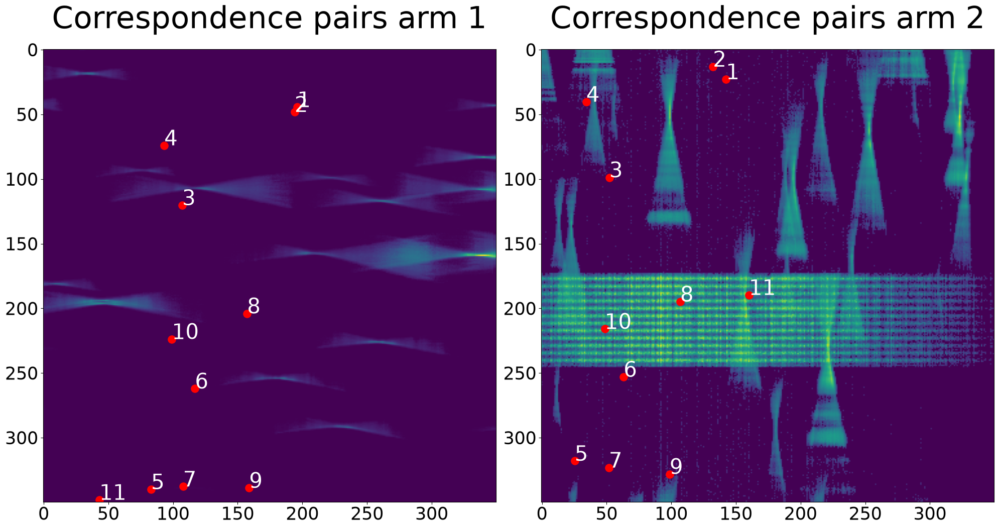

In [35]:
correspondence_pairs_1 = correspondence_pairs[:, 0, :]
correspondence_pairs_2 = correspondence_pairs[:, 1, :]

# quad_1 = sorted_matches[0, 0, :, :]
# quad_2 = sorted_matches[0, 1, :, :]
# quad_3 = sorted_matches[3, 0, :, :]
# quad_4 = sorted_matches[3, 1, :, :]
# quad_5 = sorted_matches[12, 0, :, :]
# quad_6 = sorted_matches[12, 1, :, :]

print("Difference metric between quads", sorted_lowest_differences[0])


# fig, ax = plt.subplots(2, 2, figsize=(10, 10))

# ax[0, 0].set_title("Arm 1")
# ax[0, 0].imshow(np.sum(arm_1, 0))
# # ax[0, 0].scatter(bead_locs_1[:, 2], bead_locs_1[:, 1], alpha=0.5, color="red")
# ax[0, 0].scatter(quad_1[:, 2], quad_1[:, 1], color = 'green')
# ax[0, 0].scatter(quad_3[:, 2], quad_3[:, 1], color = 'blue')
# ax[0, 0].scatter(quad_5[:, 2], quad_5[:, 1], color = 'orange')
# ax[0, 1].set_title("Arm 2")
# ax[0, 1].imshow(np.sum(arm_2, 0))
# # ax[0, 1].scatter(bead_locs_2[:, 2], bead_locs_2[:, 1], alpha=0.5, color="red")
# ax[0, 1].scatter(quad_2[:, 2], quad_2[:, 1], color = 'green')
# ax[0, 1].scatter(quad_4[:, 2], quad_4[:, 1], color = 'blue')
# ax[0, 1].scatter(quad_6[:, 2], quad_6[:, 1], color = 'orange')
# ax[1, 0].set_title("Correspondence pairs arm 1")
# ax[1, 0].imshow(np.sum(bg_sub_1, 0))
# ax[1, 0].scatter(
#     correspondence_pairs_1[:, 2], correspondence_pairs_1[:, 1], color="red"
# )
# ax[1, 1].set_title("Correspondence pairs arm 2")
# ax[1, 1].imshow(np.sum(bg_sub_2, 0))
# ax[1, 1].scatter(
#     correspondence_pairs_2[:, 2], correspondence_pairs_2[:, 1], color="red"
# )
# plt.tight_layout()

# for i, pair in enumerate(correspondence_pairs):
#     ax[1, 0].annotate(i + 1, (pair[0, 2], pair[0, 1]), color = 'white')
#     ax[1, 1].annotate(i + 1, (pair[1, 2], pair[1, 1]), color = 'white')

figsize = (20, 20)
fig, ax = plt.subplots(1, 2, figsize=figsize)
ax[0].tick_params(axis="both", which="major", labelsize=25)
ax[1].tick_params(axis="both", which="major", labelsize=25)


ax[0].set_title("Correspondence pairs arm 1", fontsize=figsize[0] * 2.2, pad=30)
ax[0].imshow(np.sum(bg_sub_1, 2))
ax[0].scatter(
    correspondence_pairs_1[:, 0],
    correspondence_pairs_1[:, 1],
    color="red",
    s=figsize[0] * 6,
)
ax[1].set_title("Correspondence pairs arm 2", fontsize=figsize[0] * 2.2, pad=30)
ax[1].imshow(np.sum(bg_sub_2, 2), norm=PowerNorm(gamma=0.4))
ax[1].scatter(
    correspondence_pairs_2[:, 0],
    correspondence_pairs_2[:, 1],
    color="red",
    s=figsize[0] * 6,
)
plt.tight_layout()

for i, pair in enumerate(correspondence_pairs):
    ax[0].annotate(
        i + 1, (pair[0, 0], pair[0, 1]), color="white", fontsize=figsize[0] * 1.5
    )
    ax[1].annotate(
        i + 1, (pair[1, 0], pair[1, 1]), color="white", fontsize=figsize[0] * 1.5
    )

plt.savefig("imgs/numbered_correspondence_pairs.svg", dpi=300)

### Calculate transform w/ RANSAC

In [9]:
print("Number of correspondence pairs found: ", (correspondence_pairs.shape)[0])

correspondence_pairs_1 = correspondence_pairs[:, 0, :]
correspondence_pairs_2 = correspondence_pairs[:, 1, :]
model, inliers = ransac(
    (correspondence_pairs_2[:], correspondence_pairs_1[:]),
    SimilarityTransform,
    min_samples=6,
    residual_threshold=10,
    max_trials=100000,
)
print("Number of inliers detected: ", np.array(inliers)[inliers == True].shape)

# Generated is a point array in lab z, y, x coordinates (same reference frame as ref)
print(bead_locs_2.shape)
intermediate = model(bead_locs_2)
intermediate_correspondence = model(correspondence_pairs_1[:])
generated = intermediate[:, [2, 1, 0]]

matched_pairs = intermediate_correspondence[:, [2, 1, 0]]
print("Calculated transform: ", model)

Number of correspondence pairs found:  13
Number of inliers detected:  (11,)
(22, 3)
Calculated transform:  <SimilarityTransform(matrix=
    [[  0.97805721,   0.0712011 ,   0.03807455,   6.83820592],
     [ -0.07265515,   0.97797206,   0.03751066, -17.4137461 ],
     [ -0.0352207 ,  -0.04020228,   0.97992778,  32.73734432],
     [  0.        ,   0.        ,   0.        ,   1.        ]])>


In [10]:
registration_matrix = model
print(registration_matrix)
# print(bead_locs_2)
# print(registration_matrix(bead_locs_2))

<SimilarityTransform(matrix=
    [[  0.97805721,   0.0712011 ,   0.03807455,   6.83820592],
     [ -0.07265515,   0.97797206,   0.03751066, -17.4137461 ],
     [ -0.0352207 ,  -0.04020228,   0.97992778,  32.73734432],
     [  0.        ,   0.        ,   0.        ,   1.        ]])>


### Plot Projections

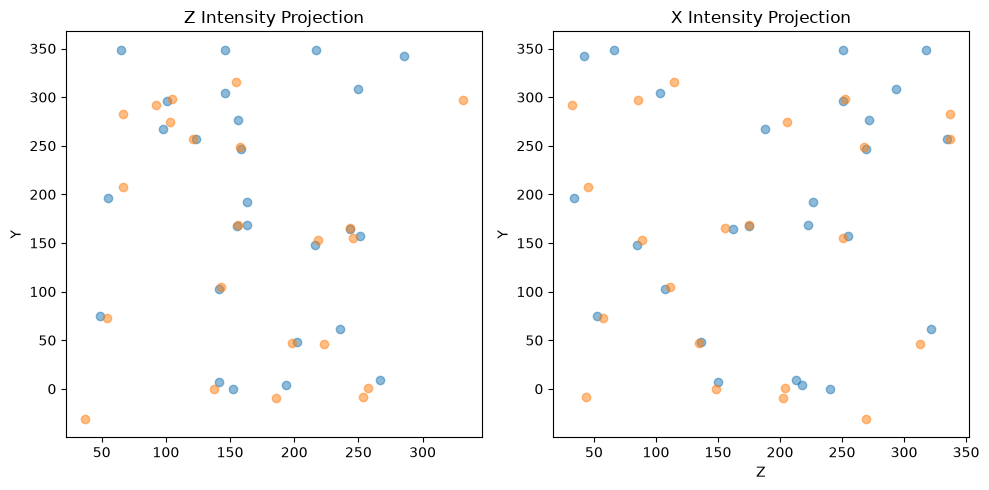

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].scatter(bead_locs_1[:, 2][:], bead_locs_1[:, 1][:], alpha=0.5)
ax[0].scatter(generated[:, 0], generated[:, 1], alpha=0.5)
ax[0].set_title("Z Intensity Projection")
ax[0].set_ylabel("Y")
ax[1].set_xlabel("X")
ax[1].scatter(bead_locs_1[:, 0][:], bead_locs_1[:, 1][:], alpha=0.5)
ax[1].scatter(generated[:, 2], generated[:, 1], alpha=0.5)
# ax[1].scatter(ref_tform_recovered[:, 0], ref_tform_recovered[:, 1], alpha = 0.5)
ax[1].set_title("X Intensity Projection")
ax[1].set_ylabel("Y")
ax[1].set_xlabel("Z")
plt.tight_layout()

(13, 2)
194
6115
144
15971


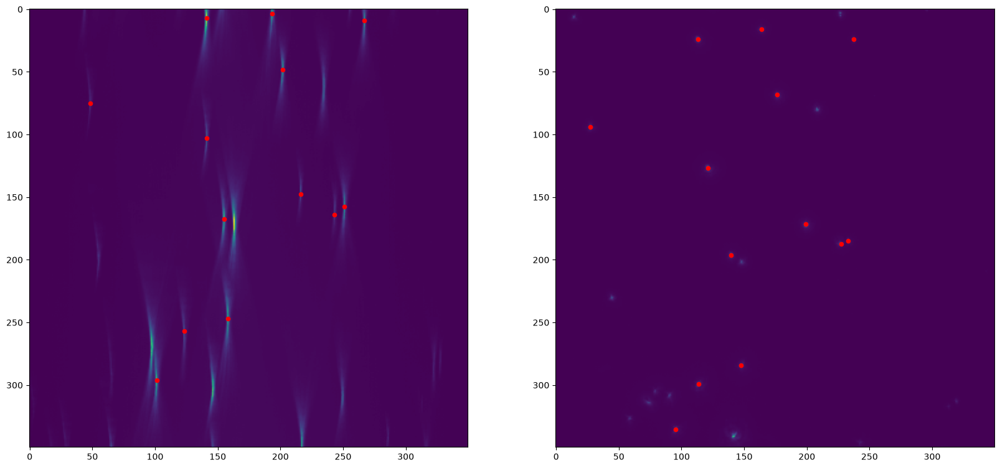

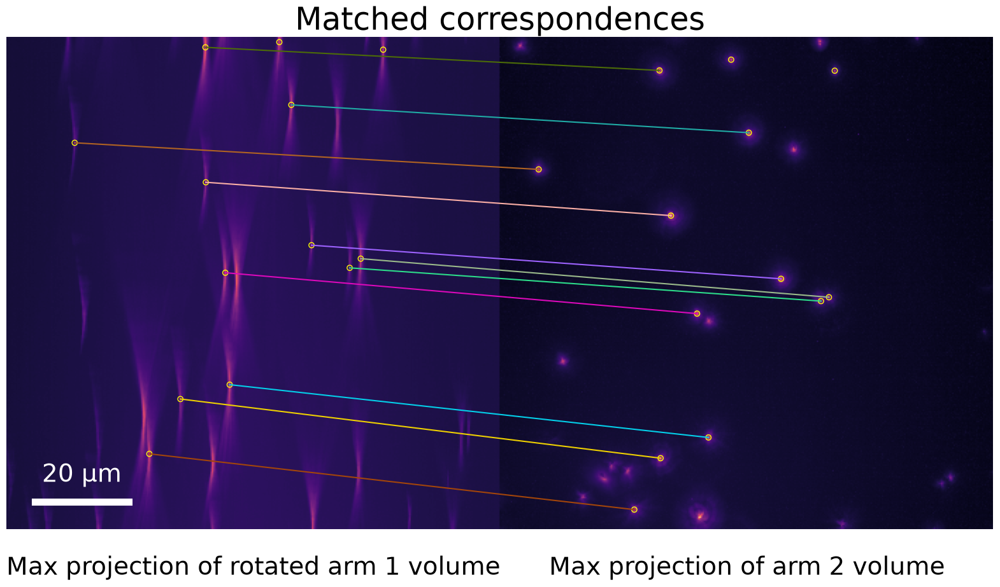

In [70]:
keypoints0 = np.array(
    list(zip(correspondence_pairs_1[:, 1], correspondence_pairs_1[:, 2]))
)
keypoints1 = np.array(
    list(zip(correspondence_pairs_2[:, 1], correspondence_pairs_2[:, 2]))
)

print(keypoints0.shape)
inlier_idxs = np.nonzero(inliers)[0]

fig, ax = plt.subplots(1, 2, figsize=(20, 20))

ax[0].imshow(np.max(arm_1, 0))
ax[0].scatter(keypoints0[:, 1], keypoints0[:, 0], s=20, color="red")
ax[1].imshow(np.max(arm_2, 0))
ax[1].scatter(keypoints1[:, 1], keypoints1[:, 0], s=20, color="red")

arm_1_mp = np.max(arm_1, 0)
arm_2_mp = np.max(arm_2, 0)
print(np.min(arm_1_mp[arm_1_mp != 0]))
print(np.max(arm_1_mp))
print(np.min(arm_2_mp[arm_2_mp != 0]))
print(np.max(arm_2_mp))
# scalebar parameters
pixel_size_um = 0.3   # set this to your actual voxel size
bar_length_um = 20
bar_length_px = bar_length_um / pixel_size_um

fig, ax = plt.subplots(figsize=(20, 20))
plot_matched_features(
    image0=arm_1_mp,
    image1=arm_2_mp,
    # Keypoints in row col order - y x
    keypoints0=keypoints0,
    keypoints1=keypoints1,
    keypoints_color="yellow",
    matches=np.column_stack((inlier_idxs, inlier_idxs)),
    ax=ax,
)

ax.axis("off")
ax.set_title("Matched correspondences", fontsize=35)

for im in ax.get_images():
    im.set_cmap("magma")
    im.set_norm(PowerNorm(gamma=0.4))

h0, w0 = arm_1_mp.shape[:2]

ax.text(
    w0 / 2,
    h0 + 36,
    "Max projection of rotated arm 1 volume",
    ha="center",
    va="bottom",
    fontsize=28,
)
ax.text(
    w0 + arm_2_mp.shape[1] / 2,
    h0 + 36,
    "Max projection of arm 2 volume",
    ha="center",
    va="bottom",
    fontsize=28,
)

# --- scalebar, bottom left corner ---
x_start = 20
y_pos = h0 - 20
ax.plot([x_start, x_start + bar_length_px], [y_pos, y_pos], color='white', linewidth=8)
ax.text(
    x_start + bar_length_px / 2,
    y_pos - 10,
    f'{bar_length_um} µm',
    color='white',
    ha='center',
    va='bottom',
    fontsize=28,
)

plt.savefig("imgs/correspondence_matching_w_lines.svg", dpi=300)
plt.show()

### Post processing - Calculate avg affine trasnform

In [13]:
def average_affine(affine_transform_array):
    num_affine_matrices = affine_transform_array.shape[0]
    translation_total = np.zeros(3).T
    rotation_total = np.zeros((3, 3))
    for transform in affine_transform_array:
        translation = transform[:-1, -1]
        translation_total += translation

        rotation = transform[:-1, :3]
        rotation_total += rotation

    translation_avg = translation_total / num_affine_matrices
    M = rotation_total / num_affine_matrices

    U, D, V_transpose = svd(M)

    Q = U @ V_transpose

    affine_avg = np.eye(4)
    affine_avg[0:3, 0:3] = Q
    affine_avg[:-1, 3] = translation_avg

    return affine_avg


affine_transforms = np.array([affine_1, affine_2])


avg_affine = average_affine(affine_transforms)
print("Average affine transform = ", avg_affine)
print("Affine transform 1 = ", affine_1)
print("Affine transform 2 = ", affine_2)

NameError: name 'affine_1' is not defined

# PSF retrieval

## PSF arm 1

### Pre-processing

(299, 1017, 1036)
Downsampled PSF shape is:  (38, 1017, 1036)


Median filtering: 100%|██████████| 38/38 [00:08<00:00,  4.31it/s]


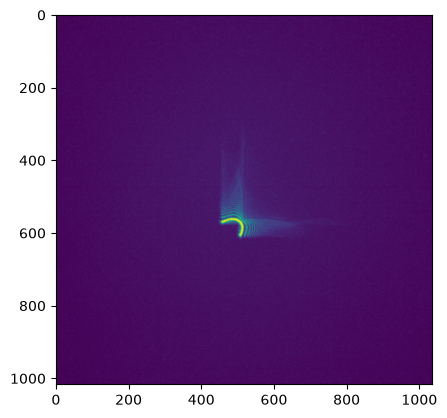

In [4]:
# Load in our raw PSF
psf = tifffile.imread(r"data/reconstruction_1/psf/psf_7.1.tif")[:-1, :, :] + 0.0
print(psf.shape)

# I will downsample the PSF in z just to speed things up a bit
downsample_factor = 8
psf = psf[::downsample_factor, :, :]
print("Downsampled PSF shape is: ", psf.shape)


# Iterate over z and perform a median filter step. This is a lazy way of getting rid of hot pixels (we can do a more sophisticated treatment later...)
for z in tqdm(range(psf.shape[0]), desc="Median filtering"):
    psf[z, :, :] = ndimage.median_filter(psf[z, :, :], 3)
    psf[z, :, :] -= np.mean(psf[z, :30, :30])
    psf[z, :, :][psf[z, :, :] <= 0] = 0
    psf[z, :, :] /= np.max(psf[z, :, :])

plt.imshow(np.max(psf, 0))

(38, 1017, 1036)
(38, 600, 600)


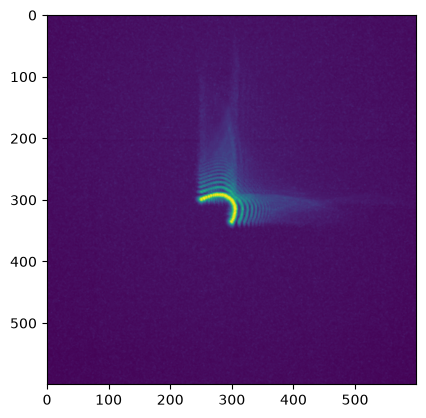

In [5]:
# This cell just crops the PSF out around the brightest pixel in the central plane
print(psf.shape)
central_slice = psf.shape[0] // 2
crop = 300  # Defines the size of the PSF
y, x = np.unravel_index(
    psf[central_slice, :, :].argmax(), psf[central_slice, :, :].shape
)
psf_cropped = psf[:, y - crop : y + crop, x - crop : x + crop].copy()
print(psf_cropped.shape)
plt.imshow(np.max(psf_cropped, 0))

In [6]:
def remove_background(psf, iterations, dist=150):
    """
    Crude function to remove background from the ZYX PSF
    """
    for i in tqdm(range(iterations)):
        for j in range(psf.shape[0]):
            psf[j, :, :] -= np.max(psf[j, -dist:, -dist:])
            psf[j, :, :][psf[j, :, :] <= 0] = 0
            psf[j, :, :] /= np.max(psf[j, :, :])
    return psf


def remove_mean_noise_iterative(psf, iterations):
    sample_region_size = (psf.shape[1] // 10, psf.shape[2] // 10)
    mean_noise = np.sum(
        psf[0, sample_region_size[0] :, sample_region_size[1] :], axis=(0, 1)
    ) / (sample_region_size[0] * sample_region_size[1])
    capped = np.where((psf - mean_noise) > 0, psf - mean_noise, 0)
    for i in tqdm(range(iterations), desc="Removing background noise"):
        mean_noise = np.sum(
            capped[0, : sample_region_size[0], : sample_region_size[1]], axis=(0, 1)
        ) / (sample_region_size[0] * sample_region_size[1])
        capped = np.where((capped - mean_noise) > 0, capped - mean_noise, 0)
    return capped

100%|██████████| 1/1 [00:00<00:00, 14.80it/s]


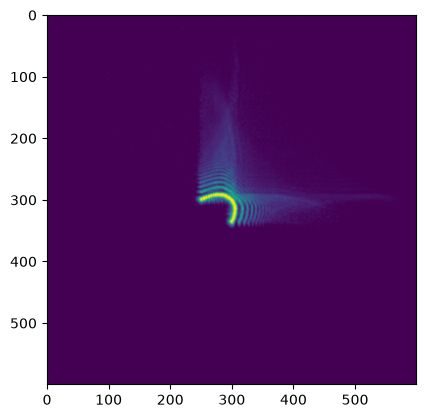

In [7]:
# This cell crudely rempves the background - you might want to see if you can come up with a better solution here!
psf_bg_removed = remove_background(psf_cropped, 1, 150)
plt.imshow(np.max(psf_bg_removed, 0))

Text(0.5, 1.0, 'XY Projection')

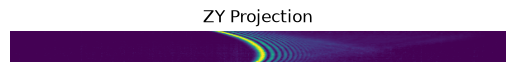

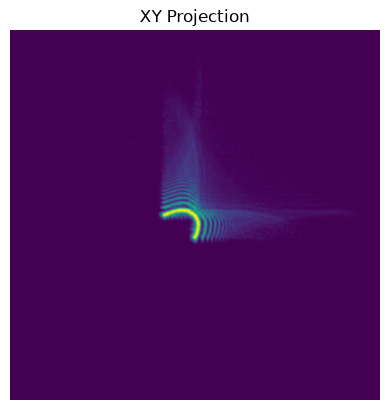

In [8]:
fig, ax = plt.subplots(1, 1)

ax.imshow(np.max(psf_cropped, 1))
ax.set_axis_off()
ax.set_title("ZY Projection")

fig, ax = plt.subplots(1, 1)

ax.imshow(np.max(psf_cropped, 0))
ax.set_axis_off()
ax.set_title("XY Projection")

### Phase retrieval

In [9]:
def recover_pupil(
    psf,
    na,
    wavelength,
    n_immersion,
    pixel_size,
    num_pixels,
    magnification,
    z_range,
    z_interval,
    n_iterations=5,
):

    # We begin by generating an unaberrated PSF using the same optical parameters.
    # This provides the defocus phase terms and the pupil aperture of the ideal system.
    unaberrated_psf = PSF(
        na=na,
        wavelength=wavelength,
        n_immersion=n_immersion,
        pixel_size=pixel_size,
        magnification=magnification,
        num_pixels=num_pixels,
        phasemask=("cubic", 0),
        z_range=z_range,
        z_interval=z_interval,
    )

    # Our initial estimate of the pupil is simply the clear aperture with no phase.
    # This corresponds to an ideal, unaberrated pupil.
    pupil = unaberrated_psf.pupil_aperture.copy()
    z_dim = psf.shape[0]

    for i in tqdm(range(n_iterations), desc="Recovering phase"):

        # Apply the appropriate defocus phase to the pupil for each axial plane.
        # This produces the pupil function as it appears at each defocused plane.
        defocused_pupils = unaberrated_psf._defocus * pupil

        # Propagate each defocused pupil to the image plane.
        # The Fourier transform gives the complex amplitude of the PSF.
        psf_amplitude = np.zeros_like(defocused_pupils, dtype=np.complex128)
        for k in range(z_dim):
            psf_amplitude[k] = np.fft.fftshift(np.fft.fftn(defocused_pupils[k]))

        # Extract the phase of the complex field at the image plane.
        phase = np.angle(psf_amplitude)

        # Replace the amplitude with the measured one.
        # This enforces that the simulated PSF matches the recorded intensity.
        mag = np.sqrt(psf)

        # Combine the measured amplitude with the recovered phase.
        psf_amplitude = mag * np.exp(1j * phase)

        # Back‑propagate each plane to the pupil.
        # The inverse Fourier transform returns the pupil field corresponding to each z-plane.
        otf_amplitude = np.zeros_like(psf_amplitude, dtype=np.complex128)
        for k in range(z_dim):
            otf_amplitude[k] = np.fft.ifftn(np.fft.ifftshift(psf_amplitude[k]))

        # Remove the defocus phase from each plane to recover the in‑focus pupil estimate.
        otf_amplitude *= unaberrated_psf.inverse_defocus

        # Average the recovered pupil across all axial planes,
        # and enforce the physical aperture set by the numerical aperture.
        pupil = np.mean(otf_amplitude, axis=0) * unaberrated_psf.pupil_aperture

    return pupil

In [10]:
print(psf_bg_removed.shape)

pupil = recover_pupil(
    psf=psf_bg_removed,
    na=0.3,
    wavelength=0.520,
    n_immersion=1.33,
    pixel_size=6.5,
    z_range=148,
    z_interval=1 * downsample_factor,
    magnification=22.2,
    n_iterations=50,
    num_pixels=600,
)

(38, 600, 600)


Recovering phase: 100%|██████████| 50/50 [02:34<00:00,  3.08s/it]


Text(0.5, 1.0, 'Recovered pupil phase')

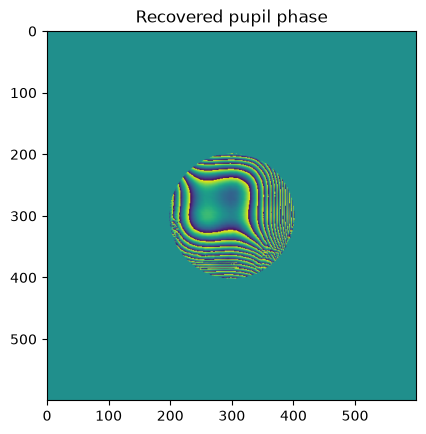

In [11]:
plt.imshow(np.angle(pupil))
plt.title("Recovered pupil phase")

### Zernike Decomposition

In [12]:
# Define mapping of noll index to name of Zernike mode [1]
zernike_names = {
    "1": "Piston",
    "2": "X-Tilt",
    "3": "Y-Tilt",
    "4": "Defocus",
    "5": "Y-Primary-Astigmatism",
    "6": "X-Primary-Astigmatism",
    "7": "Y-Primary-Coma",
    "8": "X-Primary-Coma",
    "9": "Y-Trefoil",
    "10": "X-Trefoil",
    "11": "Primary-Spherical",
    "12": "X-Secondary-Astigmatism",
    "13": "Y-Secondary-Astigmatism",
    "14": "X-Tetrafoil",
    "15": "Y-Tetrafoil",
    "16": "X-Secondary-Coma",
    "17": "Y-Secondary-Coma",
    "18": "X-Secondary-Trefoil",
    "19": "Y-Secondary-Trefoil",
    "20": "X Pentafoil",
    "21": "Y-Pentafoil",
    "22": "Secondary Spherical",
    "23": "Y-Tertiary-Astigmatism",
    "24": "X-Tertiary-Astigmatism",
    "25": "Y-Secondary-Tetrafoil",
    "26": "X-Secondary-Tetrafoil",
}


class ZernikeDecomposition:
    """
    Object to handle the decomposition of a phase-retrieved pupil-function.

    Attributes
    ----------
    kx : numpy array
         meshgrid of pupil-coordinates (units: spatial frequency). Designed
         such that the kx attribute of a PSF object can be passed here.
    ky : numpy array
         meshgrid of pupil-coordinates in y-direction.
    na : float
         The NA of the system. Needed to calculate the pupil diameter
    wavelength : float
         The wavelength of the system. Needed to calculate the pupil
         diameter.


    Methods
    -------
    _polar_pupil : covert to polar pupil coordinates
    _calc_rho_valid : calculate where the Zernikes are valid (over the unit circle)
    _calculate_aperture_mask : Returns a pupil mask of unity over the pupil, zero
                               elsewhere
    _noll_to_mn : convert Noll index to mn indices
    _calculate_radial_function : Calculate the radial part of the Zernike polynomial
                                 for a given noll index
    calculate_zernike : Calculate the full Zernike polynomial for a given noll
                        index
    _calculate_zernikes : Calculate an array of Zernike polynomials for a list/array
                          of noll indices
    fit_zernikes : Least square fit an array of Zernikes to a retrieved pupil
                   function.
    reconstruct_from_coefs : Reconstruct a 3D PSF with the cleaned-up pupil.

    References
    ----------
    [1] Hanser, B.M., Gustafsson, M.G., Agard, D.A. and Sedat, J.W., 2001, April.
    Phase retrieval     of widefield microscopy point spread functions.
    In Three-Dimensional and Multidimensional Microscopy: Image Acquisition and
    Processing VIII (Vol. 4261, pp. 60-68). International Society for Optics
    and Photonics.

    """

    def __init__(self, kx, ky, na, wavelength):

        # Assign internals
        self.na = na
        self.wavelength = wavelength
        self.kx = kx
        self.ky = ky

        # Convert pupil coordinates from cartesian to polar
        self.rho, self.phi = self._polar_pupil(kx, ky)

        # Zernike polynomials are only defined over the unit circle.
        # Need to create a mask for where this is true
        self.mask = self._calculate_aperture_mask()
        self.rho_valid = self._calc_rho_valid()

    def _polar_pupil(self, x, y):
        """Method to convert the pupil coords from cartesian to polar.
        Normalised such that the NA falls at 1"""
        rho = np.sqrt(x**2 + y**2) / (2 * np.pi * self.na / self.wavelength)
        phi = np.arctan2(y, x)
        return (rho, phi)

    def _calc_rho_valid(self):
        """Zernikes are opnly defined over the unit circle. This method returns
        only the valid coordinates, which will be determined by the NA"""
        rho_valid = self.rho.copy()
        rho_valid[rho_valid > 1] = 0
        return rho_valid

    def _calculate_aperture_mask(self):
        """Unity mask over the pupil, zero elsewhere"""
        rho_valid = self._calc_rho_valid()
        mask = rho_valid.copy()
        mask[mask != 0] = 1  # Set all valid points to 1
        return mask

    def _noll_to_mn(self, noll_index):
        """Method to convert the Noll index to nm indices - required to actually generate the polynomials."""
        # assert noll_index is valid
        assert noll_index >= 1, "Noll index must be >= 1."
        n = ((-1 + np.sqrt(8 * (noll_index - 1) + 1)) / 2).astype(int)
        p = noll_index - (n * (n + 1)) / 2.0
        m = int((p + (n % 2)) / 2.0) * 2 - (n % 2)

        if m != 0:
            if noll_index % 2 == 0:
                sign = 1
            else:
                sign = -1
            m *= sign

        return m, n

    def _calculate_radial_function(self, m, n):
        """Method to calculate the radial part of a given
        Zernike polynomial from nm index."""
        R = np.zeros(self.rho_valid.shape)
        m = np.abs(m)
        for i in range(0, int((n - m) / 2) + 1):

            R += np.array(
                self.rho_valid ** (n - 2 * i)
                * (((-1) ** (i)) * math.factorial(n - i))
                / (
                    math.factorial(i)
                    * math.factorial(int(0.5 * (n + m) - i))
                    * math.factorial(int(0.5 * (n - m) - i))
                ),
                dtype="float",
            )
        return R

    def calculate_zernike(self, noll):
        """Method to caluclate a Zernike polynomial for the pupil coordinates
        of the specified noll index."""
        # calculate indixes
        m, n = self._noll_to_mn(noll)

        # calculate radial function
        radialZernike = self._calculate_radial_function(m, n)

        if m == 0:
            zernike = np.sqrt(n + 1) * radialZernike
        else:
            if m > 0:
                zernike = np.sqrt(2 * (n + 1)) * radialZernike * np.cos(m * self.phi)
            else:
                m = abs(m)
                zernike = np.sqrt(2 * (n + 1)) * radialZernike * np.sin(m * self.phi)
        return zernike

    def _calculate_zernikes(self, noll_indices, hide_progress=False):
        """Method to create an array of zernike polynomials for
        least squares fitting."""
        zerns = np.zeros((len(noll_indices), self.kx.shape[0], self.kx.shape[1]))
        for noll in tqdm(
            range(len(noll_indices)), desc="Calculating Zernikes", disable=hide_progress
        ):
            zerns[noll, :, :] = self.calculate_zernike(noll_indices[noll])
        return zerns

    def fit_zernikes(self, function, noll_indices, phasewrapped=True):
        """Method for fitting Zernikes to a pupil function."""

        # check the function we wish to fit to is not complex
        assert function.dtype != "complex128", "Function can not be complex."

        # If the function is phasewrapped, we need to try and unwrap it here
        # (Fitting really only works to unwrapped phase)
        if phasewrapped:
            function = unwrap_phase(function) / (2 * np.pi)
            # In my experience the skimage phase unwrapping is better than the numpy
            # Not really sure why this is the case
            # And there is a factor of 2pi introduced here - I need to be careful to remember this
            # when regenerating the pupil

        # We only consider points that fall within the NA
        within_na = self.rho <= 1

        # create array of zernikes
        zerns = self._calculate_zernikes(noll_indices, hide_progress=False)

        # Note: These are *not* phase-wrapped and so we don't need to unwrap them here

        # We only consider points that fall within the NA
        zerns = zerns[
            :, within_na
        ].T  # Prep for least squares fitting, see numpy docs for details

        # Finally we perform a least-squares fit here.
        fit = np.linalg.lstsq(zerns, function[within_na], rcond=None)
        return fit[0]  # only return the coefficients for now

    def reconstruct_from_coefs(self, coefs, nolls, hide_progress=False):
        """Method to reconstruct a pupil function from zernike coefficients"""
        nolls = np.array(nolls)
        coefs = np.array(coefs)
        assert (
            nolls.shape == coefs.shape
        ), "Must provide the same number of noll indices as coefficients."
        reconstruction = np.zeros(self.kx.shape)

        for i in tqdm(
            range(len(coefs)), desc="Reconstructing Pupil", disable=hide_progress
        ):

            reconstruction += self.calculate_zernike(nolls[i]) * coefs[i]
        reconstruction = np.angle(np.exp(1j * 2 * np.pi * reconstruction))  # re-wrap
        return reconstruction * self.mask

In [13]:
p = PSF(
    na=0.3,
    wavelength=0.525,
    n_immersion=1.33,
    pixel_size=6.5,
    num_pixels=600,
    magnification=22.2,
    phasemask=("cubic", 0),
    z_range=1,
    z_interval=1,
)

kx = p._k_x
ky = p._k_y
zernike_decomposer = ZernikeDecomposition(kx=kx, ky=ky, na=0.3, wavelength=0.525)

In [30]:
num_nolls_to_fit = 50
nolls = np.arange(1, num_nolls_to_fit)

# Next we decompose the pupil -> both the phase and the magnitide. This step performs the least squares fit
phase_decomposition = zernike_decomposer.fit_zernikes(
    function=np.angle(pupil), noll_indices=nolls
)
magnitude_decomposition = zernike_decomposer.fit_zernikes(
    function=np.abs(pupil), noll_indices=nolls
)

Calculating Zernikes: 100%|██████████| 49/49 [00:00<00:00, 64.73it/s]


In [31]:
# We can now use these to regenerate the cleaned-up pupil function. We should only need 10-20 polynomials to reconstruct, but it might take a bit
# of trial and error to get the best fit with experimental data.
num_nolls_to_reconstruct = 12

# The reconstruction requires us to provide the list of noll coefficients. This is simply just a list starting from 1 up to the
# maximum noll index we want
reconstruction_nolls = np.arange(1, num_nolls_to_reconstruct)

# The reconstruction is simply a linear combination of the Zernike coefficients that we wish to use, where the coefficients are those we
# calculated above
reconstructed_phase = zernike_decomposer.reconstruct_from_coefs(
    phase_decomposition[: num_nolls_to_reconstruct - 1], reconstruction_nolls
)
reconstructed_magnitude = zernike_decomposer.reconstruct_from_coefs(
    magnitude_decomposition[: num_nolls_to_reconstruct - 1], reconstruction_nolls
)

Reconstructing Pupil: 100%|██████████| 11/11 [00:00<00:00, 107.36it/s]


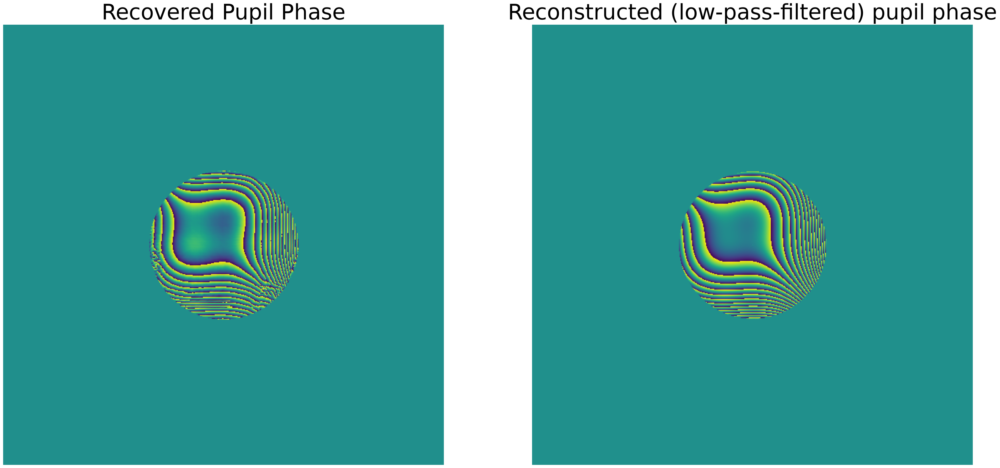

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(40, 20))

ax[0].imshow(np.angle(pupil), cmap = 'viridis')
ax[0].set_title("Recovered Pupil Phase", fontsize=50)
ax[0].axis("off")
ax[1].imshow(reconstructed_phase, cmap = 'viridis')
ax[1].set_title("Reconstructed (low-pass-filtered) pupil phase", fontsize=50)
ax[1].axis("off")

plt.savefig("imgs/reconstructed_pupil_phase.svg", dpi=300)

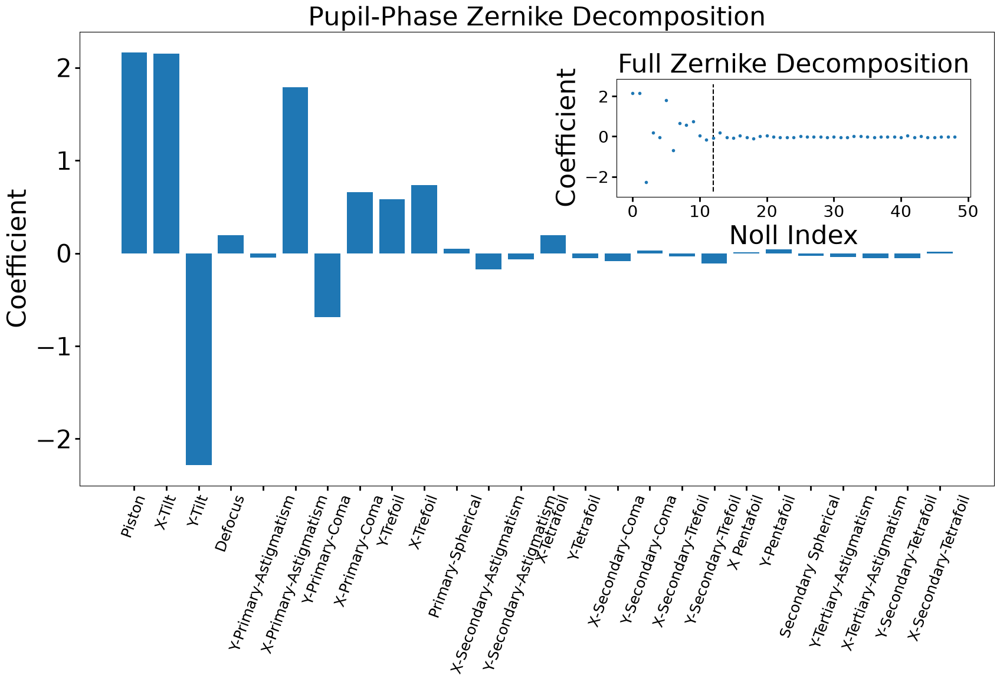

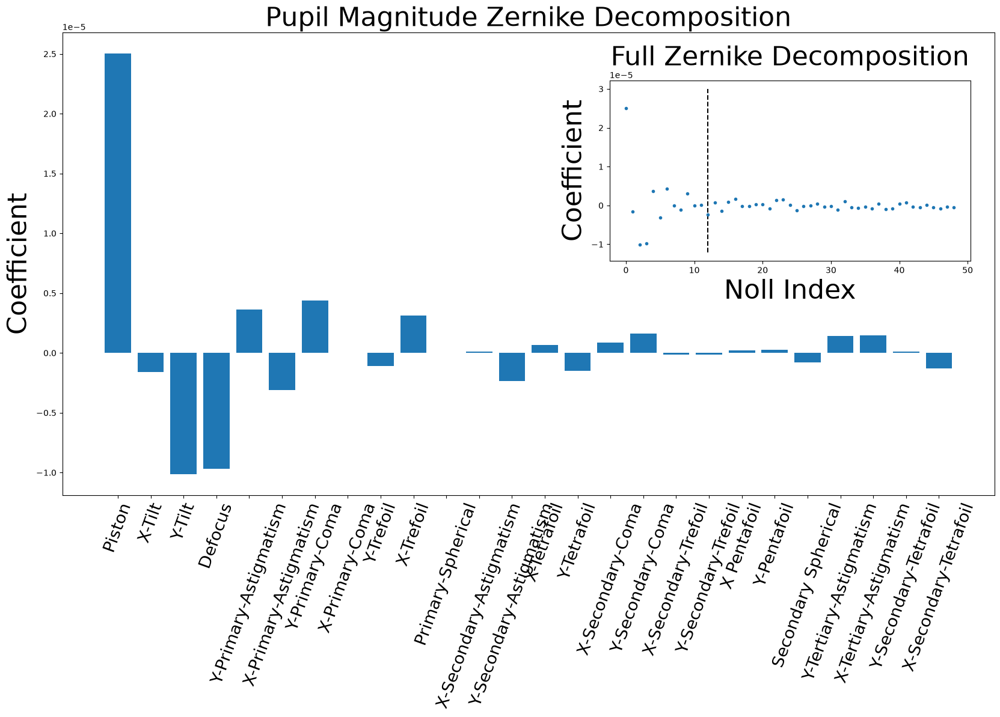

In [ ]:
x_coord = list(np.arange(0, len(zernike_names)))
fig, ax_main = plt.subplots(figsize=(2ax_inset.tick_params(axis='both', which='major', labelsize=20, length=6, width=2)
0, 10))
ax_main.tick_params(axis='both', which='major', labelsize=30, length=6, width=2)
ax_main.set_title("Pupil-Phase Zernike Decomposition", fontsize = 32)
ax_main.bar(x_coord, phase_decomposition[:26])
ax_main.set_xticks(x_coord)  # values
ax_main.set_xticklabels(zernike_names.values(), rotation=70, fontsize = 18)
# labels
ax_main.set_ylabel("Coefficient", fontsize = 32)

left, bottom, width, height = [0.58, 0.6, 0.3, 0.2]
ax_inset = fig.add_axes([left, bottom, width, height])
ax_inset.set_xlabel("Noll Index", fontsize = 32)
ax_inset.set_ylabel("Coefficient", fontsize = 32)
ax_inset.set_title("Full Zernike Decomposition", fontsize = 32)
vline_pos = num_nolls_to_reconstruct
ax_inset.vlines(
    vline_pos,
    linestyles="dashed",
    ymin=np.min(phase_decomposition * 1.2),
    ymax=np.max(phase_decomposition * 1.2),
    color="k",
)
ax_inset.plot(phase_decomposition, ".")

# Finally we plot the zernike decomposition
fig, ax_main = plt.subplots(figsize=(20, 10))
ax_main.set_title("Pupil Magnitude Zernike Decomposition", fontsize = 32)
ax_main.bar(x_coord, magnitude_decomposition[:26])
ax_main.set_xticks(x_coord)  # values
ax_main.set_xticklabels(zernike_names.values(), rotation=70, fontsize = 20)
# labels
ax_main.set_ylabel("Coefficient", fontsize = 32)

left, bottom, width, height = [0.58, 0.5, 0.3, 0.3]
ax_inset = fig.add_axes([left, bottom, width, height])
ax_inset.set_xlabel("Noll Index", fontsize = 32)
ax_inset.set_ylabel("Coefficient", fontsize = 32)
ax_inset.set_title("Full Zernike Decomposition", fontsize = 32)
ax_inset.vlines(
    vline_pos,
    linestyles="dashed",
    ymin=np.min(magnitude_decomposition * 1.2),
    ymax=np.max(magnitude_decomposition * 1.2),
    color="k",
)
ax_inset.plot(magnitude_decomposition, ".")
plt.savefig("imgs/zernike_decomp.svg", dpi=300)

### Regenerate simulated PSF

In [51]:
regen_phasemask = reconstructed_magnitude * np.exp(1j * reconstructed_phase)
regen_psf_arm_1 = PSF(
    na=0.3,
    wavelength=0.52,
    n_immersion=1.33,
    num_pixels=600,
    pixel_size=6.5,
    magnification=22.2,
    phasemask_array=regen_phasemask,
    z_range=100,
    z_interval=1,
    phasemask=regen_phasemask,
)

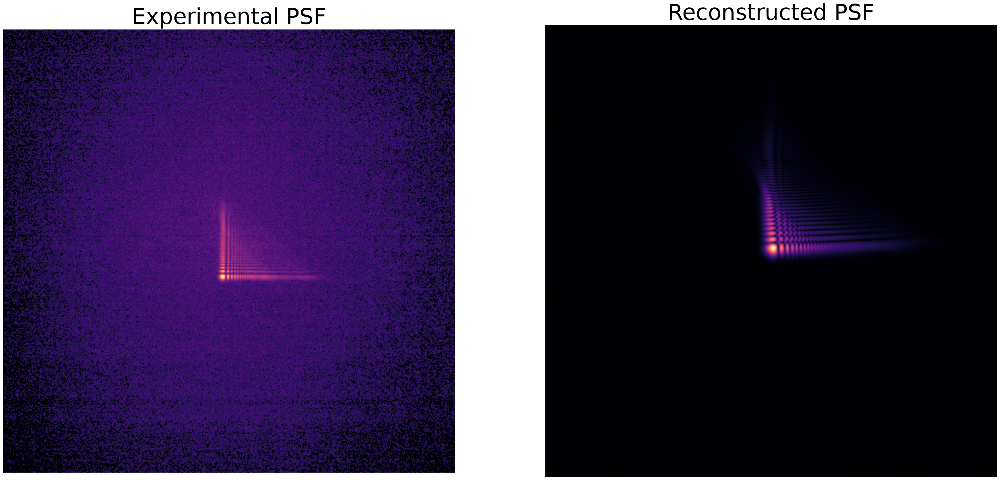

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(40, 20))

ax[0].imshow(psf[16, :, :], cmap="magma", norm=PowerNorm(gamma=0.4))
ax[0].set_title("Experimental PSF", fontsize=50)
ax[0].axis("off")
ax[1].imshow(regen_psf_arm_1.psf[100, :, :], cmap="magma", norm=PowerNorm(gamma=0.4))
ax[1].set_title("Reconstructed PSF", fontsize=50)
ax[1].axis("off")

plt.savefig("imgs/reconstructed_pupil_phase.svg", dpi=300)

## PSF arm 2

### Pre-processing

(299, 680, 694)
Downsampled PSF shape is:  (38, 680, 694)


Median filtering: 100%|██████████| 38/38 [00:06<00:00,  5.78it/s]


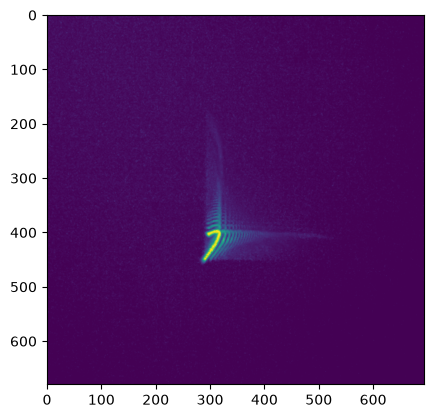

In [52]:
# Load in our raw PSF
psf = tifffile.imread(r"data/reconstruction_1/psf/psf_7.2.tif")[:-1, :, :] + 0.0
print(psf.shape)


# I will downsample the PSF in z just to speed things up a bit
downsample_factor = 8
psf = psf[::downsample_factor, :, :]
print("Downsampled PSF shape is: ", psf.shape)


# Iterate over z and perform a median filter step. This is a lazy way of getting rid of hot pixels (we can do a more sophisticated treatment later...)
for z in tqdm(range(psf.shape[0]), desc="Median filtering"):
    psf[z, :, :] = ndimage.median_filter(psf[z, :, :], 3)
    psf[z, :, :] -= np.mean(psf[z, :30, :30])
    psf[z, :, :][psf[z, :, :] <= 0] = 0
    psf[z, :, :] /= np.max(psf[z, :, :])

plt.imshow(np.max(psf, 0))

(38, 680, 694)
(38, 540, 540)


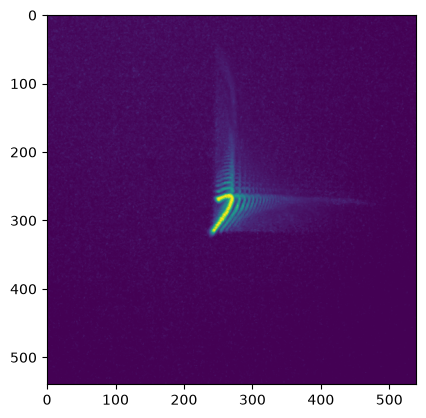

In [53]:
# This cell just crops the PSF out around the brightest pixel in the central plane
print(psf.shape)
central_slice = psf.shape[0] // 2
crop = 270  # Defines the size of the PSF
y, x = np.unravel_index(
    psf[central_slice, :, :].argmax(), psf[central_slice, :, :].shape
)
psf_cropped = psf[:, y - crop : y + crop, x - crop : x + crop].copy()
print(psf_cropped.shape)
plt.imshow(np.max(psf_cropped, 0))

100%|██████████| 1/1 [00:00<00:00,  6.75it/s]


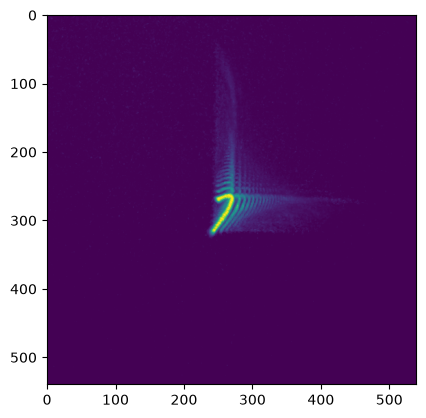

In [54]:
# This cell crudely rempves the background - you might want to see if you can come up with a better solution here!
psf_bg_removed = remove_background(psf_cropped, 1, 150)
plt.imshow(np.max(psf_bg_removed, 0))

Text(0.5, 1.0, 'XY Projection')

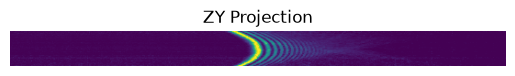

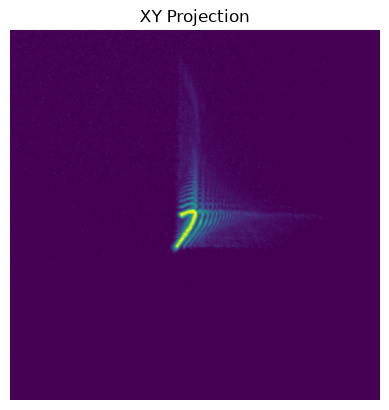

In [55]:
fig, ax = plt.subplots(1, 1)

ax.imshow(np.max(psf_cropped, 1))
ax.set_axis_off()
ax.set_title("ZY Projection")

fig, ax = plt.subplots(1, 1)

ax.imshow(np.max(psf_cropped, 0))
ax.set_axis_off()
ax.set_title("XY Projection")

### Phase Retrieval

In [56]:
print(psf_bg_removed.shape)

pupil = recover_pupil(
    psf=psf_bg_removed,
    na=0.3,
    wavelength=0.520,
    n_immersion=1.33,
    pixel_size=6.5,
    z_range=148,
    z_interval=1 * downsample_factor,
    magnification=22.2,
    n_iterations=50,
    num_pixels=540,
)

(38, 540, 540)


Recovering phase: 100%|██████████| 50/50 [02:28<00:00,  2.96s/it]


Text(0.5, 1.0, 'Recovered pupil phase')

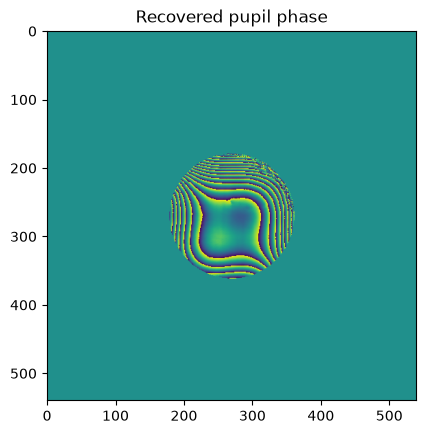

In [57]:
plt.imshow(np.angle(pupil))
plt.title("Recovered pupil phase")

### Zernike Decomposition

In [58]:
p = PSF(
    na=0.3,
    wavelength=0.525,
    n_immersion=1.33,
    pixel_size=6.5,
    num_pixels=540,
    magnification=22.2,
    phasemask=("cubic", 0),
    z_range=1,
    z_interval=1,
)

kx = p._k_x
ky = p._k_y
zernike_decomposer = ZernikeDecomposition(kx=kx, ky=ky, na=0.3, wavelength=0.525)

In [59]:
num_nolls_to_fit = 100
nolls = np.arange(1, num_nolls_to_fit)

# Next we decompose the pupil -> both the phase and the magnitide. This step performs the least squares fit
phase_decomposition = zernike_decomposer.fit_zernikes(
    function=np.angle(pupil), noll_indices=nolls
)
magnitude_decomposition = zernike_decomposer.fit_zernikes(
    function=np.abs(pupil), noll_indices=nolls
)

Calculating Zernikes: 100%|██████████| 99/99 [00:02<00:00, 37.29it/s]


Reconstructing Pupil: 100%|██████████| 11/11 [00:00<00:00, 124.14it/s]


Text(0.5, 1.0, 'Reconstructed (low-pass-filtered) pupil phase')

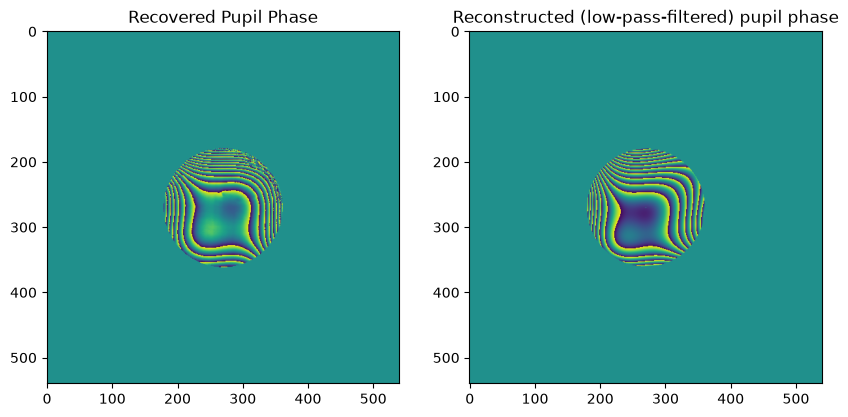

In [60]:
# We can now use these to regenerate the cleaned-up pupil function. We should only need 10-20 polynomials to reconstruct, but it might take a bit
# of trial and error to get the best fit with experimental data.
num_nolls_to_reconstruct = 12

# The reconstruction requires us to provide the list of noll coefficients. This is simply just a list starting from 1 up to the
# maximum noll index we want
reconstruction_nolls = np.arange(1, num_nolls_to_reconstruct)

# The reconstruction is simply a linear combination of the Zernike coefficients that we wish to use, where the coefficients are those we
# calculated above
reconstructed_phase = zernike_decomposer.reconstruct_from_coefs(
    phase_decomposition[: num_nolls_to_reconstruct - 1], reconstruction_nolls
)
reconstructed_magnitude = zernike_decomposer.reconstruct_from_coefs(
    magnitude_decomposition[: num_nolls_to_reconstruct - 1], reconstruction_nolls
)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(np.angle(pupil))
ax[0].set_title("Recovered Pupil Phase")
ax[1].imshow(reconstructed_phase)
ax[1].set_title("Reconstructed (low-pass-filtered) pupil phase")

### Regenerate Simulated PSF

In [61]:
regen_phasemask = reconstructed_magnitude * np.exp(1j * reconstructed_phase)
regen_psf_arm_2 = PSF(
    na=0.3,
    wavelength=0.52,
    n_immersion=1.33,
    num_pixels=540,
    pixel_size=6.5,
    magnification=22.2,
    phasemask_array=regen_phasemask,
    z_range=100,
    z_interval=1,
    phasemask=regen_phasemask,
)

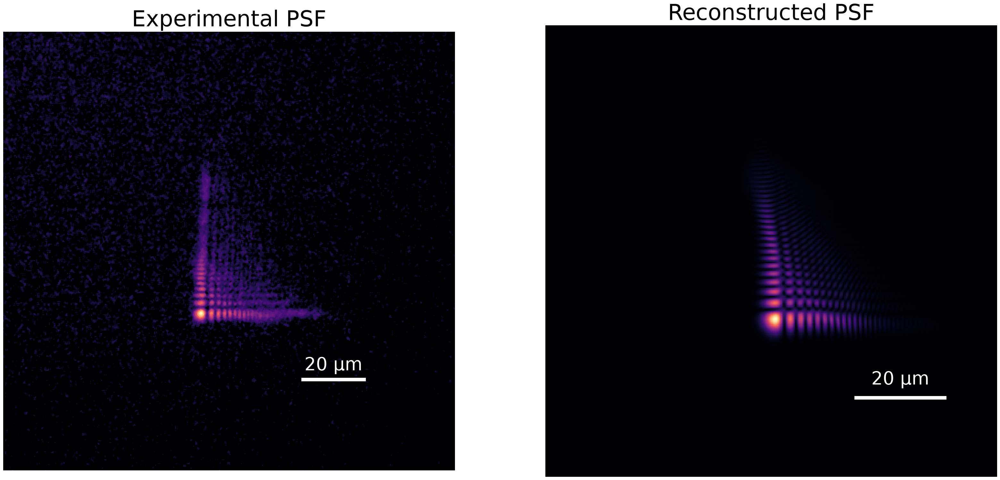

In [69]:

# scalebar parameters
pixel_size_um = 0.3   # e.g. 0.3 µm/pixel — set this to your actual voxel size
bar_length_um = 20    # desired scalebar length in µm
bar_length_px = bar_length_um / pixel_size_um

fig, ax = plt.subplots(1, 2, figsize=(40, 20))

img0 = psf[16, 100:-100, 100:-100]
img1 = regen_psf_arm_2[100, 50:-150, 100:-100]

ax[0].imshow(img0, cmap="magma", norm=PowerNorm(gamma=0.5))
ax[0].set_title("Experimental PSF", fontsize=50)
ax[0].axis("off")
ax[1].imshow(img1, cmap="magma", norm=PowerNorm(gamma=0.6))
ax[1].set_title("Reconstructed PSF", fontsize=50)
ax[1].axis("off")

# --- scalebar for panel 0 ---
x_start_0 = img0.shape[1] - bar_length_px - 100
y_pos_0 = img0.shape[0] - 100
ax[0].plot([x_start_0, x_start_0 + bar_length_px], [y_pos_0, y_pos_0], color='white', linewidth=8)
ax[0].text(x_start_0 + bar_length_px/2, y_pos_0 - 10, f'{bar_length_um} µm',
           color='white', ha='center', fontsize=40)

# --- scalebar for panel 1 ---
x_start_1 = img1.shape[1] - bar_length_px - 40
y_pos_1 = img1.shape[0] - 60
ax[1].plot([x_start_1, x_start_1 + bar_length_px], [y_pos_1, y_pos_1], color='white', linewidth=8)
ax[1].text(x_start_1 + bar_length_px/2, y_pos_1 - 10, f'{bar_length_um} µm',
           color='white', ha='center', fontsize=40)

plt.savefig("imgs/reconstructed_psf.svg", dpi=300)

# Deconvolution

In [ ]:
def vol2_to_1(volume):
    # Function that takes a volume and maps it from cam2 to cam1. In this simulation, it is simply a rotation of the volume,
    # which is performed quickly using np.swapaxes. In real experiments, there will be an additional step required, which is
    # the 3D registration you will calculate in calibration.

    # Perform the initial rotation.
    rotated = np.swapaxes(volume, 0, 2)

    registered = registration_matrix.inverse(rotated)
    return registered


def vol1_to_2(volume):
    # Function that takes a volume and maps it from cam1 to cam2. In this simulation, it is simply a rotation of the volume,
    # which is performed quickly using np.swapaxes. In real experiments, there will be an additional step required, which is
    # the 3D registration you will calculate in calibration.

    # Perform the initial rotation.
    rotated = np.swapaxes(volume, 0, 2)

    registered = affine_transform(rotated, registration_matrix.params)
    return registered

In [ ]:
def forward_project(volume, psf):
    # Forward projection of the 3D-2D RL algorithm.
    # This is our model of how images are formed in the microscope: the image we observe is the sum of 2D convolutions between the
    # PSF and the true object, at each defocus.
    projection = np.zeros((volume.shape[1], volume.shape[2]))
    for z in range(volume.shape[0]):
        projection += signal.fftconvolve(volume[z, :, :], psf[z, ::, :], "same")
    return projection


def backward_project(image, psf):
    # Backward projection of the 2D-3D RL algorithm.
    # Takes a 2D image and "projects" it back to 3D space. (If confusing, compare with the backward projection in the orginal RL notebook I sent...)
    projection = np.zeros((psf.shape[0], image.shape[0], image.shape[1]))
    for z in range(projection.shape[0]):
        projection[z, :, :] = signal.fftconvolve(image, psf[z, ::-1, ::-1], "same")
    return projection


def rl_2d_to_3d(image, psf, iterations=1, estimate=None):
    # Implementation of the 2D-3D RL algorith, for a single camera and PSF.
    if estimate is None:
        estimate = np.ones((psf.shape[0], image.shape[0], image.shape[1]))

    for iteration in range(iterations):
        # Implement the forward projection: what would the image look like, if our current estimate was correct?
        forward_projection = forward_project(estimate, psf)

        # For safety, threshold out any zeros (this shouldn't be needed, but just in case of precision leak...)
        forward_projection[forward_projection <= 0] = 1e20

        # What is the "discrepancy" between the forward projection and the actual image we recorded? (Image space)
        discrepancy_image = image / forward_projection

        # Map this "discrepancy" image back to 3D space
        discrepancy_object = backward_project(image=discrepancy_image, psf=psf)

        # Update our estimate with element-wise multiplication.
        estimate *= discrepancy_object

    return estimate


def rl_tomographic(image_cam1, image_cam2, psf1, psf2, iterations=1, estimate=None):
    # Implementation of the tomographic RL algorithm. Essentially, for each "global" iteration, we perform a single iteration of 2D-3D Rl
    # for each camera. We then average the "solutions" from each of these, and repeat for the required number of iterations. We'll see below how
    # This converges to a 3D reconstruction!
    if estimate is None:
        estimate = np.ones((psf1.shape[0], image_cam1.shape[0], image_cam1.shape[1]))

    for iteration in tqdm(
        range(iterations), desc="Perforing tomographic reconstruction..."
    ):
        # Perform an iteration of RL for cam 1...
        estimate_cam1 = rl_2d_to_3d(image_cam1, psf1, iterations=1, estimate=estimate)

        # Now we need to map our volume to cam 2 and do the same there
        estimate_mapped_t0_cam2 = vol1_to_2(estimate)
        estimate_cam2 = rl_2d_to_3d(
            image_cam2, psf2, iterations=1, estimate=estimate_mapped_t0_cam2
        )

        # We simply average the updated estimates here - and then apply them to our previous estimate by multiplying them together
        estimate *= 0.5 * (estimate_cam1 + estimate_cam2)

    return estimate

In [ ]:
image_arm_1 = io.imread("data/reconstruction_1/deconv/reconstruction_7.1.tif")
image_arm_2 = io.imread("data/reconstruction_1/deconv/reconstruction_7.2.tif")
print(image_arm_1.shape)

print(registration_matrix.params)
test = affine_transform(arm_1, registration_matrix.params)


# reconstruction_combined = rl_tomographic(image_cam1=image_arm_1, image_cam2=image_arm_2, psf1=regen_psf_arm_1.psf, psf2=regen_psf_arm_2.psf, iterations=3, estimate=None)

(1400, 1400)
[[ 9.68393749e-01  3.38172131e-02  2.02925269e-02  4.30126173e+01]
 [-3.52091120e-02  9.65993037e-01  7.04245230e-02  1.10844921e+01]
 [-1.77682015e-02 -7.11033833e-02  9.66421463e-01  7.46848186e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [74]:
# sol_cam1 = rl_2d_to_3d(image=image_arm_1, psf=regen_psf_arm_1.psf, iterations=2)
# sol_cam2 = vol1_to_2(rl_2d_to_3d(image=image_arm_2, psf=regen_psf_arm_2.psf, iterations=2))

KeyboardInterrupt: 

In [ ]:
sol_cam2 = vol1_to_2(
    rl_2d_to_3d(image=image_arm_2, psf=regen_psf_arm_2.psf, iterations=2)
)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
cmap = "Greys_r"
ax[0].imshow(np.max(reconstruction_combined, 0), cmap=cmap), ax[0].set_title(
    "Max XY"
), ax[0].set_xlabel("X"), ax[0].set_ylabel("Y")
ax[1].imshow(np.max(reconstruction_combined, 1), cmap=cmap), ax[1].set_title(
    "Max ZX"
), ax[1].set_xlabel("X"), ax[1].set_ylabel("Z")
ax[2].imshow(np.max(reconstruction_combined, 2), cmap=cmap), ax[2].set_title(
    "Max ZY"
), ax[2].set_xlabel("Y"), ax[2].set_ylabel("Z")

(700, 700, 3)


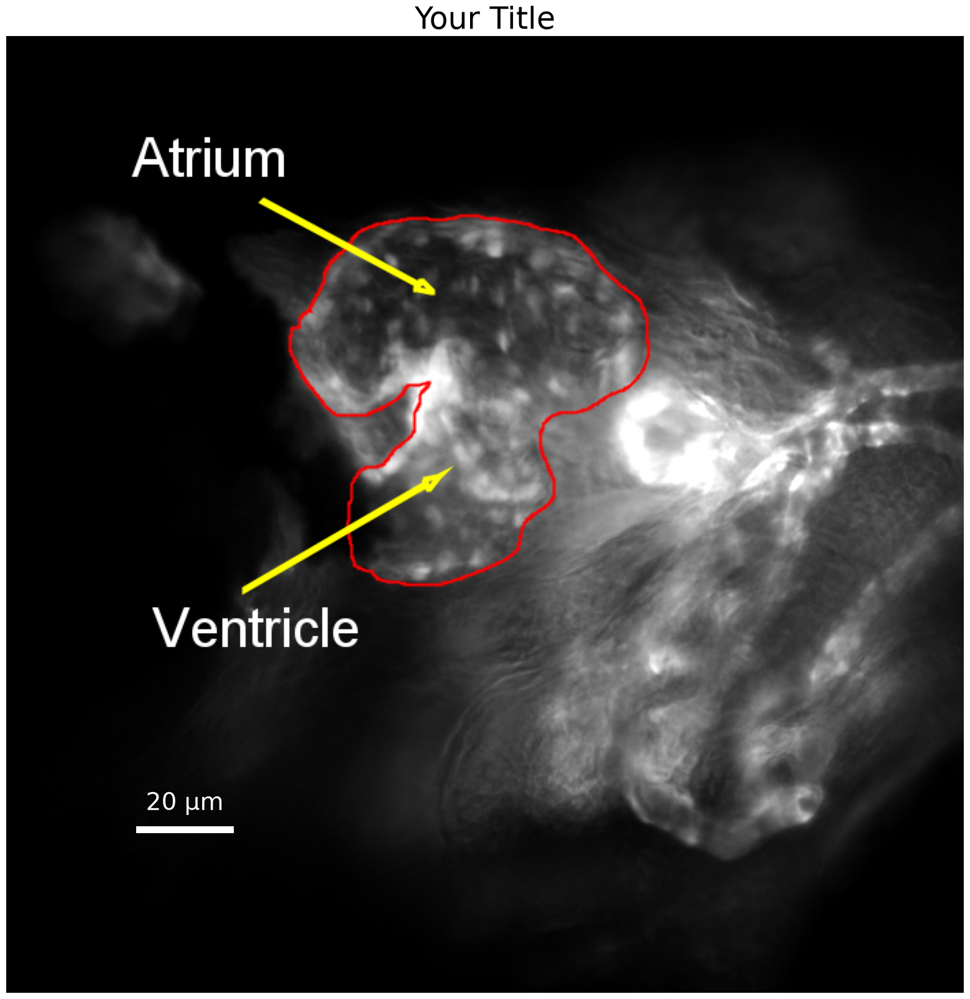

In [87]:
heart_img = tifffile.imread('imgs/heart_good.tif')
print(heart_img.shape)

# scalebar parameters
pixel_size_um = 0.3   # set this to your actual voxel size
bar_length_um = 20
bar_length_px = bar_length_um / pixel_size_um
# if it has an alpha channel, drop it so imshow treats it as plain RGB
if heart_img.ndim == 3 and heart_img.shape[-1] == 4:
    heart_img = heart_img[..., :3]


fig, ax = plt.subplots(figsize=(20, 20))

img = heart_img  # e.g. psf[16, 100:-100, 100:-100]

ax.imshow(img)
ax.set_title("Your Title", fontsize=35)
ax.axis("off")

h, w = img.shape[:2]

# --- scalebar, bottom left corner ---
x_start = bar_length_px + 30
y_pos = h - 120
ax.plot([x_start, x_start + bar_length_px], [y_pos, y_pos], color='white', linewidth=8)
ax.text(
    x_start + bar_length_px / 2,
    y_pos - 10,
    f'{bar_length_um} µm',
    color='white',
    ha='center',
    va='bottom',
    fontsize=28,
)

plt.savefig("imgs/heart_good.svg", dpi=300)
plt.show()